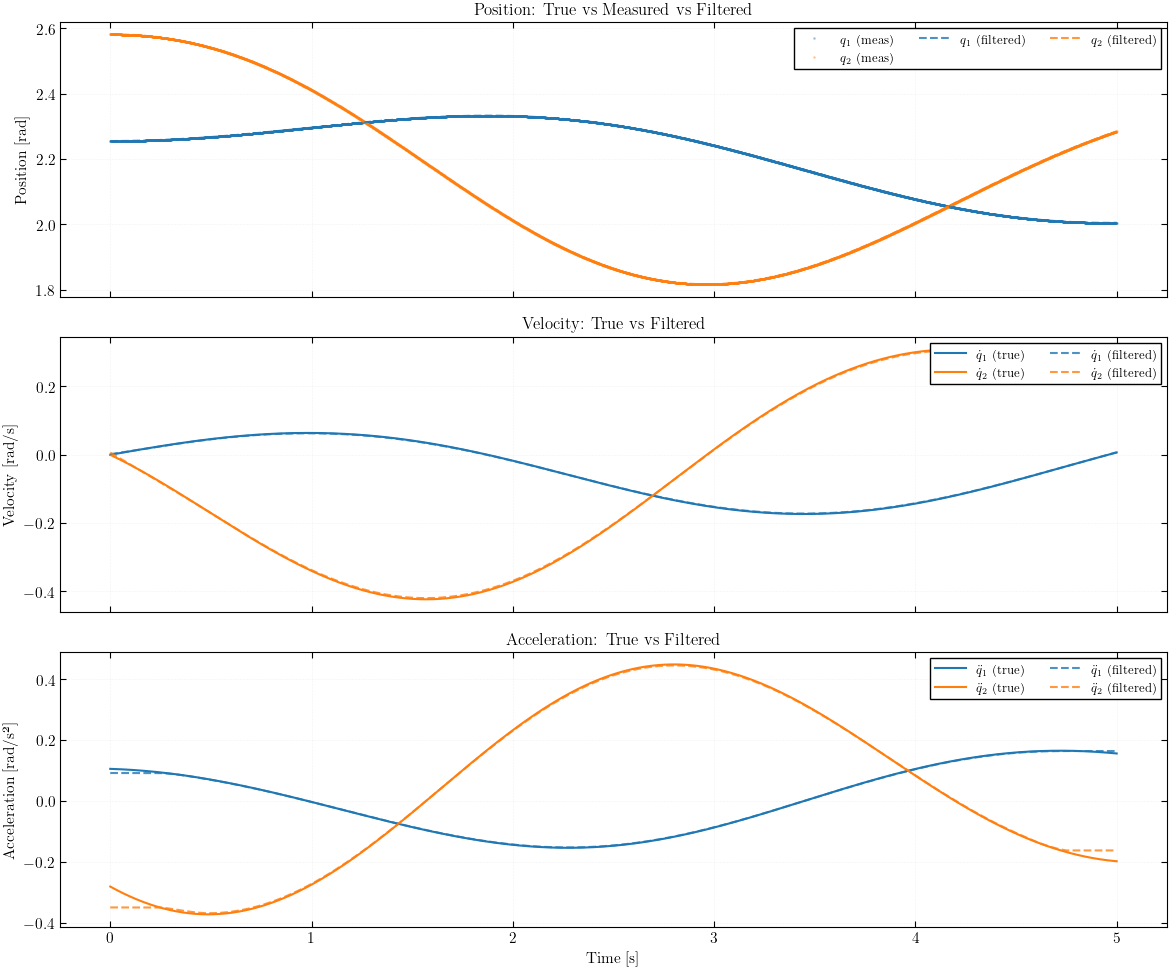

In [42]:
import numpy as np
from scipy.io import loadmat
from scipy.signal import savgol_filter, savgol_coeffs
import matplotlib.pyplot as plt


def dataset_to_iddata(dataset, K, F):

    runs = dataset.runs
    # When using squeeze_me=True, single dimension structs become 1D arrays
    if not isinstance(runs, np.ndarray):
        runs = np.array([runs])

    R = runs.size

    # --- first pass: total number of samples ---
    Ni = np.zeros(R, dtype=int)
    for i in range(R):
        Ni[i] = runs[i].x_true.shape[0]  # length of this run
    Ntot = Ni.sum()

    # Preallocate
    data = {}
    data["t"]        = np.zeros(Ntot)
    data["q_meas"]   = np.zeros((2, Ntot))
    data["qd_filt"]  = np.zeros((2, Ntot))
    data["qdd_filt"] = np.zeros((2, Ntot))
    data["q"]        = np.zeros((2, Ntot))
    data["qd"]       = np.zeros((2, Ntot))
    data["qdd"]      = np.zeros((2, Ntot))
    data["tau_meas"] = np.zeros((2, Ntot))
    data["KE"]       = np.zeros(Ntot)
    data["momentum"] = np.zeros((2,Ntot))

    # assume constant dt across runs
    dt = runs[0].time[1] - runs[0].time[0]
    data["dt"] = float(dt)

    idx0 = 0  # starting index in the global arrays for each run
    for i in range(R):
        r = runs[i]
        ti = np.asarray(r.time).ravel()
        Ni_i = Ni[i]

        start = idx0
        end = idx0 + Ni_i  # Python slice is [start, end)

        ke_run = np.asarray(r.KE).ravel()
        ke_run = ke_run.reshape(-1)[:Ni_i]

        # Fill raw (unfiltered) data
        for k in range(Ni_i):
            j = start + k  # global index
            xk = np.asarray(r.x_true[k, :]).ravel()   # [th1 th2 dth1 dth2]
            yk = np.asarray(r.y_meas[k, :]).ravel()   # [th1 th2 dth1 dth2]
            pk = np.asarray(r.p[k, :]).ravel()   # [p1 p2]

            data["t"][j]            = ti[k]
            data["q_meas"][:, j]    = yk[0:2]         # measured positions
            data["q"][:, j]         = xk[0:2]         # true positions
            data["qd"][:, j]        = xk[2:4]         # true velocities
            data["qdd"][:, j]       = np.asarray(r.ddq[k, :]).ravel()
            data["tau_meas"][:, j]  = np.asarray(r.u_applied[k, :]).ravel()
            data["KE"][j] = ke_run[k]
            data["momentum"][:,j] = pk[0:2]

        # ---- Filtering for this run ----
        # Position filtering with Savitzky–Golay (sgolayfilt)
        q_meas_run = data["q_meas"][:, start:end]  # shape (2, Ni_i)

        q_filt1 = savgol_filter(q_meas_run[0, :], window_length=F, polyorder=K, mode="interp")
        q_filt2 = savgol_filter(q_meas_run[1, :], window_length=F, polyorder=K, mode="interp")
        data["q_filt"] = data.get("q_filt", np.zeros((2, Ntot)))
        data["q_filt"][0, start:end] = q_filt1
        data["q_filt"][1, start:end] = q_filt2

        # # Get the differentiation coefficients
        # g1 = savgol_coeffs(F, K, deriv=1, delta=dt)
        # g2 = savgol_coeffs(F, K, deriv=2, delta=dt)

        # # Apply via convolution - both derivatives from q_filt
        # data["qd_filt"][0, start:end] = np.convolve(data["q_filt"][0, start:end], g1, mode='same')
        # data["qd_filt"][1, start:end] = np.convolve(data["q_filt"][1, start:end], g1, mode='same')
        # data["qdd_filt"][0, start:end] = np.convolve(data["q_filt"][0, start:end], g2, mode='same')
        # data["qdd_filt"][1, start:end] = np.convolve(data["q_filt"][1, start:end], g2, mode='same')

        data["qd_filt"][0, start:end] = savgol_filter(data["q_filt"][0, start:end], F, K, deriv=1, delta=dt, mode='interp')
        data["qd_filt"][1, start:end] = savgol_filter(data["q_filt"][1, start:end], F, K, deriv=1, delta=dt, mode='interp')
        data["qdd_filt"][0, start:end] = savgol_filter(data["q_filt"][0, start:end], F, K, deriv=2, delta=dt, mode='interp')
        data["qdd_filt"][1, start:end] = savgol_filter(data["q_filt"][1, start:end], F, K, deriv=2, delta=dt, mode='interp')

        # move starting index for next run
        idx0 = end

    return data


def plot_comparison(data, run_length):
    """Create figure with 3 subplots comparing true vs filtered data for one run"""
    # Only plot the first run
    idx = slice(0, run_length)
    t = data['t'][idx]
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    
    colors = ['#1f77b4', '#ff7f0e']  # Blue and orange
    
    # --- Subplot 1: Position (q) ---
    ax1 = axes[0]
    ax1.plot(t, data['q_meas'][0, idx], '.', color=colors[0], markersize=2, alpha=0.3, label='$q_1$ (meas)')
    ax1.plot(t, data['q_meas'][1, idx], '.', color=colors[1], markersize=2, alpha=0.3, label='$q_2$ (meas)')
    # ax1.plot(t, data['q'][0, idx], color=colors[0], linewidth=1.5, label='$q_1$ (true)')
    # ax1.plot(t, data['q'][1, idx], color=colors[1], linewidth=1.5, label='$q_2$ (true)')
    ax1.plot(t, data['q_filt'][0, idx], '--', color=colors[0], linewidth=1.5, alpha=0.8, label='$q_1$ (filtered)')
    ax1.plot(t, data['q_filt'][1, idx], '--', color=colors[1], linewidth=1.5, alpha=0.8, label='$q_2$ (filtered)')
    ax1.set_ylabel('Position [rad]', fontsize=11)
    ax1.set_title('Position: True vs Measured vs Filtered', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper right', ncol=3, fontsize=9)
    ax1.grid(True, alpha=0.3)
    
    # --- Subplot 2: Velocity (qd) ---
    ax2 = axes[1]
    ax2.plot(t, data['qd'][0, idx], color=colors[0], linewidth=1.5, label=r'$\dot{q}_1$ (true)')
    ax2.plot(t, data['qd'][1, idx], color=colors[1], linewidth=1.5, label=r'$\dot{q}_2$ (true)')
    ax2.plot(t, data['qd_filt'][0, idx], '--', color=colors[0], linewidth=1.5, alpha=0.8, label=r'$\dot{q}_1$ (filtered)')
    ax2.plot(t, data['qd_filt'][1, idx], '--', color=colors[1], linewidth=1.5, alpha=0.8, label=r'$\dot{q}_2$ (filtered)')
    ax2.set_ylabel('Velocity [rad/s]', fontsize=11)
    ax2.set_title('Velocity: True vs Filtered', fontsize=12, fontweight='bold')
    ax2.legend(loc='upper right', ncol=2, fontsize=9)
    ax2.grid(True, alpha=0.3)
    
    # --- Subplot 3: Acceleration (qdd) ---
    ax3 = axes[2]
    ax3.plot(t, data['qdd'][0, idx], color=colors[0], linewidth=1.5, label=r'$\ddot{q}_1$ (true)')
    ax3.plot(t, data['qdd'][1, idx], color=colors[1], linewidth=1.5, label=r'$\ddot{q}_2$ (true)')
    ax3.plot(t, data['qdd_filt'][0, idx], '--', color=colors[0], linewidth=1.5, alpha=0.8, label=r'$\ddot{q}_1$ (filtered)')
    ax3.plot(t, data['qdd_filt'][1, idx], '--', color=colors[1], linewidth=1.5, alpha=0.8, label=r'$\ddot{q}_2$ (filtered)')
    ax3.set_ylabel('Acceleration [rad/s²]', fontsize=11)
    ax3.set_xlabel('Time [s]', fontsize=11)
    ax3.set_title('Acceleration: True vs Filtered', fontsize=12, fontweight='bold')
    ax3.legend(loc='upper right', ncol=2, fontsize=9)
    ax3.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()



if __name__ == "__main__":
    # Load the same .mat file as in MATLAB
    S = loadmat("planar_2dof_dataset_no_noise_linear_friction.mat",
                squeeze_me=True, struct_as_record=False)
    dataset = S["dataset"]



    F = 501
    K = 2
    data = dataset_to_iddata(dataset, K, F)

    # Get the length of the first run
    runs = dataset.runs
    if not isinstance(runs, np.ndarray):
        runs = np.array([runs])
    run_length = runs[0].x_true.shape[0]

    plot_comparison(data, run_length)


In [43]:
runs = dataset.runs
# if not isinstance(runs, np.ndarray):
#     runs = np.array([runs])

trajectories = {"time": data["t"], "states": []}

for i, r in enumerate(runs):
    Ni = r.x_true.shape[0]
    print(f"Processing run {i+1} with {Ni} samples...")

    #THIS IS STILL NOISE FREE X
    theta1 = np.array([r.x_true[j, 0] for j in range(Ni)])
    theta2 = np.array([r.x_true[j, 1] for j in range(Ni)])
    dtheta1 = np.array([r.x_true[j, 2] for j in range(Ni)])
    dtheta2 = np.array([r.x_true[j, 3] for j in range(Ni)])

    tau1 = np.array([r.u_applied[j, 0] for j in range(Ni)])
    tau2 = np.array([r.u_applied[j, 1] for j in range(Ni)])

    # energy = np.array([compute_total_energy(r.x_true[j, :]) for j in range(Ni)])
    # momentum = np.array([compute_momentum(r.x_true[j, :]) for j in range(Ni)])

    energy = np.array([r.KE[j] for j in range(Ni)])
    momentum = np.array([r.p[j, :] for j in range(Ni)])

    # dtheta1_filt = np.array([r.qd_filt[j, 0] for j in range(Ni)])
    # dtheta2_filt = np.array([r.qd_filt[j, 1] for j in range(Ni)])

    trajectories["states"].append({
        "initial_condition": r.x_true[0, :],
        "theta1": theta1,
        "theta2": theta2,
        "dtheta1": dtheta1,
        "dtheta2": dtheta2,
        # "dtheta1_filt": dtheta1_filt,
        # "dtheta2_filt": dtheta2_filt,
        "tau1": tau1,
        "tau2": tau2,
        "p1": momentum[:, 0],
        "p2": momentum[:, 1],
        "total_energy": energy

    })

trajectories["states"]

Processing run 1 with 5001 samples...
Processing run 2 with 5001 samples...
Processing run 3 with 5001 samples...
Processing run 4 with 5001 samples...
Processing run 5 with 5001 samples...
Processing run 6 with 5001 samples...
Processing run 7 with 5001 samples...
Processing run 8 with 5001 samples...
Processing run 9 with 5001 samples...
Processing run 10 with 5001 samples...
Processing run 11 with 5001 samples...
Processing run 12 with 5001 samples...
Processing run 13 with 5001 samples...
Processing run 14 with 5001 samples...
Processing run 15 with 5001 samples...
Processing run 16 with 5001 samples...
Processing run 17 with 5001 samples...
Processing run 18 with 5001 samples...
Processing run 19 with 5001 samples...
Processing run 20 with 5001 samples...


[{'initial_condition': array([2.25496777, 2.58181318, 0.        , 0.        ]),
  'theta1': array([2.25496777, 2.25496782, 2.25496798, ..., 2.00438403, 2.0043906 ,
         2.00439733], shape=(5001,)),
  'theta2': array([2.58181318, 2.58181304, 2.58181262, ..., 2.28404779, 2.28425891,
         2.28446984], shape=(5001,)),
  'dtheta1': array([0.        , 0.00010574, 0.00021145, ..., 0.00649054, 0.00664685,
         0.00680308], shape=(5001,)),
  'dtheta2': array([ 0.        , -0.00028062, -0.0005616 , ...,  0.21121913,
          0.2110217 ,  0.21082422], shape=(5001,)),
  'tau1': array([0.02799577, 0.02799736, 0.0279989 , ..., 0.03806951, 0.03805658,
         0.03805658], shape=(5001,)),
  'tau2': array([-0.01213461, -0.0121555 , -0.01217637, ..., -0.00243871,
         -0.00244729, -0.00244729], shape=(5001,)),
  'p1': array([0.00000000e+00, 2.79947084e-05, 5.59888964e-05, ...,
         1.54743075e-03, 1.58536889e-03, 1.62329097e-03], shape=(5001,)),
  'p2': array([ 0.00000000e+00, -1.2

In [44]:
t_eval = data["t"]  # Time points
state_trajectories = trajectories["states"]  # List of dictionaries
dt = t_eval[1]-t_eval[0]

# Prepare dataset: single state transitions (x_t -> x_t+1)
X, Y, U = [], [], []

for traj in state_trajectories:
    theta1 = traj["theta1"]
    theta2 = traj["theta2"]
    p1 = traj["p1"]
    p2 = traj["p2"]
    tau1 = traj["tau1"]
    tau2 = traj["tau2"]
    
    for t in range(len(theta1) - 1):  # One-step transitions
        current_state = np.array([theta1[t], theta2[t], p1[t], p2[t]])
        next_state = np.array([theta1[t+1], theta2[t+1], p1[t+1], p2[t+1]])
        current_input = np.array([tau1[t], tau2[t]])
        
        X.append(current_state)
        Y.append(next_state)
        U.append(current_input)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)
U = np.array(U, dtype=np.float32)



In [45]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint_adjoint as odeint
import torch.nn.functional as F

def make_mlp(in_dim, out_dim, hidden=(128,128), activation=nn.Tanh):
    layers = []
    d = in_dim
    for h in hidden:
        layers.append(nn.Linear(d, h))
        layers.append(activation())
        d = h
    layers.append(nn.Linear(d, out_dim))   # last layer no activation
    return nn.Sequential(*layers)

class LowerTriangularNN(nn.Module):
    """
    This neural network outputs (N^2 + N)/2 values corresponding to
    the lower triangular entries of a symmetric matrix.

    The last-layer activation ensures diagonal positivity (Softplus + ε).
    """
    def __init__(self, n_dim, input_dim = 2, hidden_dims=(64, 64), eps=1e-3):
        super().__init__()

        self.n_dim = n_dim
        self.eps = eps

        # Number of parameters needed for lower triangular matrix
        self.out_dim = (n_dim * (n_dim + 1)) // 2

        # Build feed-forward network
        layers = []
        for h in hidden_dims:
            layers.append(nn.Linear(input_dim, h))
            layers.append(nn.Tanh())
            input_dim = h

        # Final layer outputs LT matrix entries
        layers.append(nn.Linear(input_dim, self.out_dim))

        self.net = nn.Sequential(*layers)
        self.softplus = nn.Softplus()

    def forward(self, x):
        """
        Returns a symmetric positive-definite matrix for each sample x.
        """
        batch_size = x.shape[0]

        raw_output = self.net(x)

        # Split indices: diagonal first, then off-diagonals
        L = x.new_zeros(batch_size, self.n_dim, self.n_dim)

        # Fill lower-triangular entries
        idx = 0
        for i in range(self.n_dim):
            # Diagonal entry: force positivity
            L[:, i, i] = self.softplus(raw_output[:, idx]) + self.eps
            # L[:, i, i] = raw_output[:, idx] + self.eps

            idx += 1

            # Off-diagonal entries
            for j in range(i + 1, self.n_dim):
                L[:, j, i] = raw_output[:, idx]
                idx += 1

        # Construct symmetric PD matrix:
        M = L @ L.transpose(1, 2)
        return M


class ActuatorNN(nn.Module):
    """Map q -> B(q) (n x m) matrix. Input: q [B,n], Output: [B, n, m]."""
    def __init__(self, q_dim, u_dim, hidden=(128,128)):
        super().__init__()
        out_dim = q_dim * u_dim
        self.net = make_mlp(2*q_dim, out_dim, hidden=hidden)

    def forward(self, q):
        inp = torch.cat([torch.sin(q), torch.cos(q)], dim=-1)
        vec = self.net(inp)  # [B, n*m]
        Bmat = vec.view(vec.shape[0], -1, int(vec.shape[-1] // q.shape[-1]))  # [B, n, m]
        return Bmat

# Define the Hamiltonian Neural Network 
class HamiltonianNN(nn.Module):
    # def __init__(self, input_dim=6, hidden_dim=200, output_dim=1): old
    def __init__(self, q_dim, mass_nn,p_dim=None):
        super().__init__()
        self.q_dim = q_dim
        self.p_dim = q_dim if p_dim is None else p_dim
        self.mass_nn = mass_nn

    def kinetic_energy(self, q, p):
        # q: [B, q_dim], p: [B, q_dim]

        #NN mass matrix:
        q2 = q[:, 1:2]               # <-- ONLY q2 used
        M = self.mass_nn(q2)                # [B, q, q]            # [B, q, q]

        # compute 0.5 p^T M p  <- NO INVERSE
        p_col = p.unsqueeze(-1)            # [B, q, 1]
        tmp = M @ p_col                 # [B, q, 1]
        T = 0.5 * (p_col * tmp).sum(dim=1).squeeze(-1)  # [B]
        return T

    def forward(self, q, p):
        T = self.kinetic_energy(q, p)
        return T  # H (no potential)

class HamiltonianDynamics(nn.Module):
    """
    Given HamiltonianModel H(q,p), compute (dq/dt, dp/dt) using autograd:
      dq/dt =  ∂H/∂p
      dp/dt = -∂H/∂q + damping + actuators
    """
    def __init__(self, hamiltonian_model, mass_nn=None, diss_nn=None, actuator_nn=None):
        super().__init__()
        self.hamiltonian_model = hamiltonian_model
        self.mass_nn = mass_nn
        self.diss_nn = diss_nn
        self.actuator_nn = actuator_nn

    def S_of_qp(self, q, M, Minv, p):
        # v = M @ p, shape [B, n]
        v = torch.bmm(M, p.unsqueeze(-1)).squeeze(-1)
        
        # Compute Jacobian dv/dq row by row
        B, n = q.shape
        J = torch.zeros(B, n, n, device=q.device, dtype=q.dtype)
        
        for i in range(n):
            grad_outputs = torch.zeros_like(v)
            grad_outputs[:, i] = 1.0
            J[:, i, :] = torch.autograd.grad(v, q, grad_outputs, 
                                            create_graph=True, 
                                            retain_graph=True)[0]
        
        skew = J.transpose(1, 2) - J
        S = torch.bmm(torch.bmm(Minv, skew), Minv)
        return S


    # Define the learned Hamiltonian dynamics
    def forward(self, t, x, u):
        q, p = torch.split(x, x.shape[-1]//2, dim=-1)
        q = q.requires_grad_(True)
        p = p.requires_grad_(True)
        
        H = self.hamiltonian_model(q, p)

        dH_dq, dH_dp = torch.autograd.grad(H.sum(), (q, p), create_graph=True)
        
        # Get mass matrix and inverse
        q2 = q[:, 1:2]
        M = self.mass_nn(q2)
        Minv = torch.linalg.inv(M)
        
        # Compute S matrix
        S = self.S_of_qp(q, M, Minv, p)
        
        # Damping: D = M @ D0 @ M
        D0 = self.diss_nn(q)
        # D = torch.bmm(torch.bmm(M, D0), M)
        D = torch.bmm(torch.bmm(Minv, D0), Minv)
        
        # Actuation: G = Minv @ G0
        # G0 = self.actuator_nn(q)
        # G = torch.bmm(Minv, G0)
        # actuation = torch.bmm(G, u.unsqueeze(-1)).squeeze(-1)

        #no actuation matrix; still need transformation!
        # actuation = torch.bmm(Minv, u.unsqueeze(-1)).squeeze(-1)
        if u.dim() == 1:
            u = u.unsqueeze(0)              # [1, q] or [1, u_dim]
        actuation = torch.matmul(Minv, u.unsqueeze(-1)).squeeze(-1)
        
        # === DYNAMICS FROM EQUATION (4) ===
        # dq/dt = M^{-1} @ dH/dp = M^{-1} @ (M @ p) = p (velocity!)
        # dq_dt = torch.bmm(Minv, dH_dp.unsqueeze(-1)).squeeze(-1)
        dq_dt = torch.matmul(Minv, dH_dp.unsqueeze(-1)).squeeze(-1)

        
        # dp/dt = -M^{-1} @ dH/dq + (S - D) @ dH/dp + G @ u
        # dp_dt = (
        #     -torch.bmm(Minv, dH_dq.unsqueeze(-1)).squeeze(-1)
        #     + torch.bmm(S - D, dH_dp.unsqueeze(-1)).squeeze(-1)
        #     + actuation
        # )
        dp_dt = (
            -torch.matmul(Minv, dH_dq.unsqueeze(-1)).squeeze(-1)
            + torch.matmul(S - D, dH_dp.unsqueeze(-1)).squeeze(-1)
            + actuation
        )

        
        return torch.cat([dq_dt, dp_dt], dim=-1)

class BatchDynamics(nn.Module):
    def __init__(self, dynamics, u_seq, t_grid):
        super().__init__()
        self.dynamics = dynamics
        self.u_seq = u_seq          # [B, T, u_dim]
        self.t_grid = t_grid        # [T]


    def forward(self, t, x):
        # t: scalar tensor
        idx = torch.searchsorted(self.t_grid, t, right=True) - 1
        idx = idx.clamp(0, self.u_seq.shape[1] - 1)

        u_t = self.u_seq[:, idx, :]   # [B, u_dim]
        return self.dynamics(t, x, u_t)



def rk4_step(odefunc, x, t, dt):
    # odefunc: callable(t, x) 
    k1 = odefunc(t, x)
    k2 = odefunc(t + dt/2, x + dt * k1 / 2)
    k3 = odefunc(t + dt/2, x + dt * k2 / 2)
    k4 = odefunc(t + dt,   x + dt * k3)
    x_next = x + dt * (k1 + 2*k2 + 2*k3 + k4) / 6
    return x_next


In [46]:
from sklearn.model_selection import train_test_split
import random

# -------------------------------------------------
# Reproducibility
# -------------------------------------------------
seed = 8
np.random.seed(seed)
random.seed(seed)

# -------------------------------------------------
# Optional: trajectory downsampling helper
# -------------------------------------------------
def downsample_run(run, factor):
    """
    Downsample a trajectory by an integer factor.

    Args:
        run (dict): {"x": [T, nx], "u": [T, nu], "dq": [T, ndq]}
        factor (int): downsampling factor (>= 1)

    Returns:
        dict: downsampled run
    """
    if factor == 1:
        return run

    return {
        "x":  run["x"][::factor],
        "u":  run["u"][::factor],
        "dq": run["dq"][::factor],
    }

# -------------------------------------------------
# Load time base and trajectories
# -------------------------------------------------
t_eval = data["t"]                      # Time points
state_trajectories = trajectories["states"]

dt = float(t_eval[1] - t_eval[0])
print(f"Original dt = {dt:.6f}")

# -------------------------------------------------
# Build full-resolution trajectories
# -------------------------------------------------
list_of_runs = []

for traj in state_trajectories:
    theta1  = np.asarray(traj["theta1"],  dtype=np.float32)
    theta2  = np.asarray(traj["theta2"],  dtype=np.float32)
    dtheta1 = np.asarray(traj["dtheta1"], dtype=np.float32)
    dtheta2 = np.asarray(traj["dtheta2"], dtype=np.float32)
    p1      = np.asarray(traj["p1"],      dtype=np.float32)
    p2      = np.asarray(traj["p2"],      dtype=np.float32)
    tau1    = np.asarray(traj["tau1"],    dtype=np.float32)
    tau2    = np.asarray(traj["tau2"],    dtype=np.float32)

    T = len(theta1)

    x_seq  = np.stack([theta1, theta2, p1, p2], axis=1)   # [T, 4]
    u_seq  = np.stack([tau1, tau2], axis=1)               # [T, 2]
    dq_seq = np.stack([dtheta1, dtheta2], axis=1)         # [T, 2]

    assert x_seq.shape == (T, 4)
    assert u_seq.shape == (T, 2)
    assert dq_seq.shape == (T, 2)

    list_of_runs.append({
        "x":  x_seq,
        "u":  u_seq,
        "dq": dq_seq,
    })

print(f"Prepared {len(list_of_runs)} full trajectories.")

# -------------------------------------------------
# Optional: increase dt by subsampling
# -------------------------------------------------
downsample_factor = 10   # <<< CHANGE THIS (1 = no change)

assert downsample_factor >= 1

if downsample_factor > 1:
    list_of_runs = [
        downsample_run(run, downsample_factor)
        for run in list_of_runs
    ]
    dt = dt * downsample_factor

print(f"Using dt = {dt:.6f} (downsample factor = {downsample_factor})")

# -------------------------------------------------
# Train / Validation / Test split (by trajectory)
# -------------------------------------------------
train_runs, val_test_runs = train_test_split(
    list_of_runs,
    test_size=0.20,
    random_state=seed,
    shuffle=True
)

val_runs, test_runs = train_test_split(
    val_test_runs,
    test_size=0.50,   # 10% val, 10% test
    random_state=seed + 1,
    shuffle=True
)

print("Split complete:")
print(f"   Train:      {len(train_runs)} trajectories ({len(train_runs)/len(list_of_runs)*100:.1f}%)")
print(f"   Validation: {len(val_runs)} trajectories ({len(val_runs)/len(list_of_runs)*100:.1f}%)")
print(f"   Test:       {len(test_runs)} trajectories ({len(test_runs)/len(list_of_runs)*100:.1f}%)")

# -------------------------------------------------
# Ready for dataset construction
# -------------------------------------------------
# dataset      = SequenceDataset(train_runs, seq_len_min)
# val_dataset  = SequenceDataset(val_runs,   seq_len_max)
# test_dataset = SequenceDataset(test_runs,  seq_len_max)


Original dt = 0.001000
Prepared 20 full trajectories.
Using dt = 0.010000 (downsample factor = 10)
Split complete:
   Train:      16 trajectories (80.0%)
   Validation: 2 trajectories (10.0%)
   Test:       2 trajectories (10.0%)


In [47]:
from torch.utils.data import Dataset, DataLoader

class SequenceDataset(Dataset):
    """
    Takes list_of_runs where each run is dict-like with keys 'x' (T x D) and 'u' (T x U).
    Samples contiguous sequences of length `seq_len` that *start at t0* for each run.
    """
    def __init__(self, list_of_runs, seq_len):
        self.runs = list_of_runs
        self.seq_len = int(seq_len)
        self._rebuild_start_indices()

    def _rebuild_start_indices(self):
        # Only allow sequences that start at index 0 (t0) for each run
        # self.start_indices = []
        # for run_i, run in enumerate(self.runs):
        #     T = run['x'].shape[0]
        #     if T >= self.seq_len + 1:
        #         self.start_indices.append((run_i, 0))


        # # precompute valid start indices per run
        self.start_indices = []
        for run_i, run in enumerate(self.runs):
            T = run['x'].shape[0]
            max_start = T - (self.seq_len + 1)
            if max_start >= 0:
                # store (run_i, start_idx) pairs for all valid start positions
                for s in range(0,max_start + 1,self.seq_len):
                    self.start_indices.append((run_i, s))

    def set_seq_len(self, seq_len):
        self.seq_len = int(seq_len)
        self._rebuild_start_indices()

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        run_i, s = self.start_indices[idx]
        run = self.runs[run_i]
        x_seq = run['x'][s:s+self.seq_len+1]   # length seq_len+1 for x0..x_T
        dq_seq = run['dq'][s:s+self.seq_len+1]
        u_seq = run['u'][s:s+self.seq_len]     # controls for steps 0..T-1
        return torch.from_numpy(x_seq).float(), torch.from_numpy(u_seq).float(), torch.from_numpy(dq_seq).float()




In [48]:
def get_analytical_mass_matrix(q2, params=None):
    """
    Compute analytical mass matrix for 2-link manipulator.
    
    M(q_2) = [[a1 + 2*b*cos(q2),  a2 + b*cos(q2)],
              [a2 + b*cos(q2),     a2            ]]
    
    Args:
        q2: scalar or array of joint angles
        params: dict with keys ['m1', 'm2', 'l1', 'l2', 'r1', 'r2', 'I1', 'I2']
    """
    
    # Compute inertial parameters
    a1 = params['m1'] * params['r1']**2 + params['m2'] * params['l1']**2 + params['I1']
    a2 = params['m2'] * params['r2']**2 + params['I2']
    b = params['m2'] * params['l1'] * params['r2']
    
    # Handle both scalar and array inputs
    cos_q2 = np.cos(q2) if isinstance(q2, np.ndarray) else np.cos(q2)
    
    if np.isscalar(q2):
        M = np.array([
            [a1 + 2*b*cos_q2, a2 + b*cos_q2],
            [a2 + b*cos_q2,   a2]
        ])
    else:
        # Vectorized for multiple q2 values
        N = len(q2)
        M = np.zeros((N, 2, 2))
        M[:, 0, 0] = a1 + 2*b*cos_q2
        M[:, 0, 1] = a2 + b*cos_q2
        M[:, 1, 0] = a2 + b*cos_q2
        M[:, 1, 1] = a2
    
    return M


def initialize_mass_nn_from_analytical(mass_nn, params=None, n_samples=100):
    """
    Initialize LowerTriangularNN to match analytical mass matrix M(q2).
    
    Strategy:
    1. Sample q2 values over the workspace
    2. Compute analytical M(q2) for each sample
    3. Compute corresponding Cholesky factors L(q2)
    4. Fit the neural network to predict L(q2) from q2
    
    Args:
        mass_nn: Your LowerTriangularNN instance
        params: Physical parameters dict (uses defaults if None)
        n_samples: Number of samples for initialization fitting
    """
    device = next(mass_nn.parameters()).device
    
    # Sample q2 over typical range (e.g., -π to π)
    q2_samples = np.linspace(-np.pi, np.pi, n_samples)
    
    # Compute analytical mass matrices
    M_samples = get_analytical_mass_matrix(q2_samples, params)  # [N, 2, 2]
    
    # Compute Cholesky decompositions
    L_samples = np.zeros_like(M_samples)
    for i in range(n_samples):
        try:
            L_samples[i] = np.linalg.cholesky(M_samples[i])
        except np.linalg.LinAlgError:
            # Add small regularization if not PD
            M_reg = M_samples[i] + 1e-6 * np.eye(2)
            L_samples[i] = np.linalg.cholesky(M_reg)
    
    # Extract lower triangular entries for each sample
    # Order: L[0,0], L[1,0], L[1,1]
    lt_targets = np.zeros((n_samples, 3))
    for i in range(n_samples):
        # For diagonal entries, we need to account for softplus + eps
        # Target: softplus(x) + eps = L[i,i]
        # We'll fit to raw L values and adjust final bias
        lt_targets[i, 0] = L_samples[i, 0, 0]  # L[0,0]
        lt_targets[i, 1] = L_samples[i, 1, 0]  # L[1,0]
        lt_targets[i, 2] = L_samples[i, 1, 1]  # L[1,1]
    
    # Convert to torch
    q2_tensor = torch.tensor(q2_samples, dtype=torch.float32).reshape(-1, 1).to(device)
    lt_tensor = torch.tensor(lt_targets, dtype=torch.float32).to(device)
    
    # Adjust targets for softplus on diagonal entries
    # softplus(x) + eps = target => x = inverse_softplus(target - eps)
    adjusted_targets = lt_tensor.clone()
    for diag_idx in [0, 2]:  # Diagonal positions
        target_vals = lt_tensor[:, diag_idx] - mass_nn.eps
        # Inverse softplus: log(exp(y) - 1)
        adjusted_targets[:, diag_idx] = torch.log(
            torch.exp(target_vals) - 1 + 1e-8
        )
    
    # Fit the network using simple supervised learning
    print("Fitting mass matrix NN to analytical form...")
    optimizer = torch.optim.Adam(mass_nn.parameters(), lr=1e-3)
    
    for epoch in range(500):
        optimizer.zero_grad()
        
        # Forward pass
        pred_lt = mass_nn.net(q2_tensor)
        
        # Loss on lower triangular entries
        loss = torch.mean((pred_lt - adjusted_targets)**2)
        
        loss.backward()
        optimizer.step()
        
        if (epoch + 1) % 100 == 0:
            print(f"Epoch {epoch+1}, Loss: {loss.item():.6f}")
    
    # Verify initialization
    print("\n=== Verification ===")
    test_q2 = torch.tensor([[0.0], [np.pi/4], [np.pi/2]]).to(device)
    
    for i, q2_val in enumerate([0.0, np.pi/4, np.pi/2]):
        M_analytical = get_analytical_mass_matrix(q2_val, params)
        M_nn = mass_nn(test_q2[i:i+1]).detach().cpu().numpy()[0]
        
        print(f"\nq2 = {q2_val:.3f}")
        print(f"Analytical M:\n{M_analytical}")
        print(f"NN M:\n{M_nn}")
        print(f"Error: {np.linalg.norm(M_analytical - M_nn):.6f}")
    
    return mass_nn


def initialize_mass_nn_simple(mass_nn, params=None):
    """
    Simpler initialization: just set the network to output M(0) initially.
    The network will learn the q2 dependence during training.
    
    This is faster but less accurate than the full fitting approach.
    """
    device = next(mass_nn.parameters()).device
    
    # Get mass matrix at q2 = 0
    M_zero = get_analytical_mass_matrix(0.0, params)
    
    # Add small regularization
    M_zero = M_zero + 1e-6 * np.eye(2)
    
    # Cholesky decomposition
    L_zero = np.linalg.cholesky(M_zero)
    
    # Extract lower triangular entries and adjust for softplus
    lt_entries = []
    
    # L[0,0] - diagonal
    target_val = L_zero[0, 0] - mass_nn.eps
    init_val = np.log(np.exp(target_val) - 1 + 1e-8)
    lt_entries.append(init_val)
    
    # L[1,0] - off-diagonal
    lt_entries.append(L_zero[1, 0])
    
    # L[1,1] - diagonal
    target_val = L_zero[1, 1] - mass_nn.eps
    init_val = np.log(np.exp(target_val) - 1 + 1e-8)
    lt_entries.append(init_val)
    
    lt_entries = torch.tensor(lt_entries, dtype=torch.float32)
    
    # Set final layer to output these values
    with torch.no_grad():
        final_layer = mass_nn.net[-1]
        final_layer.bias.copy_(lt_entries)
        final_layer.weight.normal_(0, 0.01)
    
    print("Initialized mass matrix NN with M(q2=0)")
    print(f"M(0) analytical:\n{M_zero}")
    
    test_input = torch.zeros(1, 1).to(device)
    M_init = mass_nn(test_input).detach().cpu().numpy()[0]
    print(f"M(0) NN initial:\n{M_init}")


def initialize_damping_nn_diagonal(diss_nn, params=None):
    """
    Initialize damping network to output diagonal D matrix.
    
    For viscous-only friction: D = diag(b1, b2)
    
    Args:
        diss_nn: LowerTriangularNN instance (input_dim=2 for q)
        params: dict with keys ['b1', 'b2'] (viscous friction coefficients)
    """
    device = next(diss_nn.parameters()).device
    
    b1 = params['b1']
    b2 = params['b2']
    
    print("\n=== Damping Matrix Initialization ===")
    print(f"Viscous friction coefficients:")
    print(f"  b1 = {b1:.6f} [N·m·s/rad]")
    print(f"  b2 = {b2:.6f} [N·m·s/rad]")
    
    # Target diagonal D matrix
    D_target = np.diag([b1, b2])
    
    print(f"\nTarget D matrix (diagonal):")
    print(f"  [{D_target[0,0]:.6f}, {D_target[0,1]:.6f}]")
    print(f"  [{D_target[1,0]:.6f}, {D_target[1,1]:.6f}]")
    
    # Cholesky: D = L @ L.T
    # For diagonal D, L is diagonal with L[i,i] = sqrt(D[i,i])
    L_target = np.sqrt(D_target)
    
    # Extract lower triangular entries: [L[0,0], L[1,0], L[1,1]]
    lt_entries = []
    
    # L[0,0] - diagonal
    target_val = L_target[0, 0] - diss_nn.eps
    init_val = np.log(np.exp(target_val) - 1 + 1e-8) if target_val > 0 else -5.0
    lt_entries.append(init_val)
    
    # L[1,0] - off-diagonal (zero for diagonal D)
    lt_entries.append(0.0)
    
    # L[1,1] - diagonal
    target_val = L_target[1, 1] - diss_nn.eps
    init_val = np.log(np.exp(target_val) - 1 + 1e-8) if target_val > 0 else -5.0
    lt_entries.append(init_val)
    
    lt_entries = torch.tensor(lt_entries, dtype=torch.float32)
    
    # Set final layer to output these values
    with torch.no_grad():
        final_layer = diss_nn.net[-1]
        final_layer.bias.copy_(lt_entries)
        final_layer.weight.normal_(0, 0.001)  # Very small weights
    
    print(f"\nCholesky factor L (for D = L @ L.T):")
    print(f"  [{L_target[0,0]:.6f}, {L_target[0,1]:.6f}]")
    print(f"  [{L_target[1,0]:.6f}, {L_target[1,1]:.6f}]")
    
    # Verify
    test_input = torch.zeros(1, 2).to(device)
    D_init = diss_nn(test_input).detach().cpu().numpy()[0]
    
    print(f"\nInitial D matrix from NN:")
    print(f"  [{D_init[0,0]:.6f}, {D_init[0,1]:.6f}]")
    print(f"  [{D_init[1,0]:.6f}, {D_init[1,1]:.6f}]")
    
    error = np.linalg.norm(D_target - D_init)
    print(f"\nError from target: {error:.6e}")
    print("="*50)
    
    return diss_nn


In [49]:
import matplotlib.pyplot as plt
# from torchdiffeq import odeint_adjoint

# hyperparams
method = 'BPTT'
scheduler_on = 'training'
batch_size = 40
# Curriculum parameters: start with short sequences and grow to max
seq_len_min = 50  # initial short sequences starting at t0
seq_len_max = 50   # maximum sequence length to train with
seq_len_val = 5000 / downsample_factor
lr = 1e-4
epochs = 0
device = torch.device("cpu") #if torch.backends.mps.is_available() else torch.device("cpu")
q_dim = 2
loss_func = 'exponential'
alpha = 0.05  # loss decay rate
lambda_H = 0.1
validation = True


anchor_start = 0 
anchor_end = 0   
anchor_decay_epochs = 1

def anchor_prob(epoch):
    t = min(1.0, epoch / anchor_decay_epochs)
    return anchor_start + (anchor_end - anchor_start) * t

# instantiate networks 
mass_nn = LowerTriangularNN(q_dim, input_dim = 1, hidden_dims=(32,32)).to(device) #input only q2
diss_nn = LowerTriangularNN(q_dim, hidden_dims=(16,16)).to(device)
actuator_nn = ActuatorNN(q_dim, u_dim=2, hidden=(2,2)).to(device)

# physical parameters (but then a bit wrong)
params = {
    'm1': 1.6237, 'l1': 0.345, 'r1': 0.283,
    'm2': 0.992, 'l2': 0.257, 'r2': 0.18,
    'I1': 0.05, 'I2': 0.008,
    'b1': 0.06,   'b2': 0.01  # Viscous friction
}

# Option 1: Full fitting of OLS parameters
initialize_mass_nn_from_analytical(mass_nn, params, n_samples=100)
initialize_damping_nn_diagonal(diss_nn, params)

# # Option 2: load trained model
# # load saved state dict (make sure path is correct)
# state = torch.load("modular_hnn_state_no_noise_linear_friction.pth", map_location=device)

# # If you saved separate state_dicts under keys, load them:
# if 'mass_nn' in state or 'diss_nn' in state or 'actuator_nn' in state:
#     if 'mass_nn' in state:
#         mass_nn.load_state_dict(state['mass_nn'])
#     if 'diss_nn' in state:
#         diss_nn.load_state_dict(state['diss_nn'])
#     if 'actuator_nn' in state:
#         actuator_nn.load_state_dict(state['actuator_nn'])
# else:
#     # if you saved a single state_dict (older variant), try to load into whole model later
#     print("Warning: expected keys mass_nn/diss_nn/actuator_nn not found in the PTH file.")

ham_model = HamiltonianNN(q_dim, mass_nn)
dynamics = HamiltonianDynamics(ham_model, mass_nn=mass_nn,diss_nn=diss_nn, actuator_nn=actuator_nn).to(device)

optim_ = optim.Adam(dynamics.parameters(), lr=lr,weight_decay=0, betas = [0.9, 0.999])
mse = nn.MSELoss()

# create dataset with initial short sequences starting at t0
dataset = SequenceDataset(list_of_runs, seq_len_min)
# validation_runs is a held-out list of trajectories
val_dataset = SequenceDataset(val_runs, seq_len_val)  # Fixed to max for full evaluation
val_dataloader = DataLoader(val_dataset, batch_size=1, shuffle=False, drop_last=False)

dynamics.to(device)

# optional LR scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim_, factor=0.5, patience=5)

train_q_loss = []
train_qdot_loss = []
train_total_loss = []

val_q_loss = []
val_qdot_loss = []
val_total_loss = []

for epoch in range(epochs):
    # seq length schedule (linear ramp)
    seq_len = int(seq_len_min + (seq_len_max - seq_len_min) * (epoch / max(1, epochs - 1)))
    seq_len = max(seq_len_min, min(seq_len, seq_len_max))
    dataset.set_seq_len(seq_len)

    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    dynamics.train()

    print(f"Epoch {epoch+1}/{epochs}  seq_len={seq_len}  batches={len(dataloader)}  available_runs={len(dataset)}")

    # accumulators for epoch averages
    epoch_q_loss_sum = 0.0
    epoch_qdot_loss_sum = 0.0
    epoch_total_loss_sum = 0.0
    num_batches = 0

    qdots_momentum = []
    qdots_hamiltonian = []
    momentum = []

    for x_seq_batch, u_seq_batch, dq_seq_batch in dataloader:
        x_seq_batch = x_seq_batch.to(device)    # [B, seq_len+1, state_dim]
        u_seq_batch = u_seq_batch.to(device)    # [B, seq_len, u_dim]
        t_span = torch.linspace(0, seq_len * dt, seq_len + 1, device=device)

        optim_.zero_grad()

        q0 = x_seq_batch[:, 0, :q_dim].clone().detach()     # [B, q_dim]
        dq0 = dq_seq_batch[:, 0, :].clone().detach()       # initial velocity [B, q_dim]

        # concatenate q0 and p0 to form initial state
        x_pred = torch.cat([q0, dq0], dim=-1).clone().detach().requires_grad_(True)

        # per-batch accumulators
        preds = []

        if method == 'ADJOINT':
            batched_dyn = BatchDynamics(dynamics, u_seq_batch, t_span)

            trajectory = odeint(
                batched_dyn,        # nn.Module, not lambda
                x_pred,
                t_span,
                method="rk4",
                options={"step_size": dt},
            )

            for step in range(1, trajectory.shape[0]):
                state_pred = trajectory[step]        # [B, state_dim]
                preds.append(state_pred)     
        if method == 'BPTT':
            for k in range(seq_len):
                u_step = u_seq_batch[:, k, :]        # [B, u_dim]
                x_prev = x_pred.clone()

                # wrap ode_fn for RK4 call (lambda capturing u_step)
                f = lambda tt, xx, u=u_step: dynamics(tt, xx, u)
                x_pred = rk4_step(f, x_pred, k * dt, dt)   # [B, D]
                preds.append(x_pred)

        # compute trajectory loss from preds (only position components)
        n_steps = len(preds)
        if loss_func == 'exponential':
            steps = torch.arange(n_steps, device=device).float()
            weights = torch.exp(-alpha * steps)
            # per-step mse (already mean over batch) -> weighted average
            weighted_ms = torch.stack([weights[i] * mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
            q_loss = weighted_ms.sum() / weights.sum()

            qdot_loss = torch.stack([
                weights[i] * mse(preds[i][:, 2:], dq_seq_batch[:,i])
                for i in range(n_steps)
            ]).sum() / weights.sum()

        elif loss_func == 'cummulative':
            per_step_ms = torch.stack([mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
            q_loss = per_step_ms.sum()

            per_step_ms = torch.stack([mse(preds[i][:, 2:], dq_seq_batch[:,i]) for i in range(n_steps)])
            qdot_loss = per_step_ms.sum()

        total_loss = q_loss + lambda_H * qdot_loss

        # backprop
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(dynamics.parameters(), 1.0)
        optim_.step()

        # accumulate epoch sums for logging
        epoch_q_loss_sum += q_loss.item()
        epoch_qdot_loss_sum += qdot_loss.item()
        epoch_total_loss_sum += total_loss.item()
        num_batches += 1

    # compute epoch averages
    if num_batches > 0:
        epoch_q_loss = epoch_q_loss_sum / num_batches
        epoch_qdot_loss = epoch_qdot_loss_sum / num_batches
        epoch_loss_total = epoch_total_loss_sum / num_batches
    else:
        epoch_q_loss = epoch_qdot_loss = epoch_loss_total = 0.0

    train_q_loss.append(epoch_q_loss)
    train_qdot_loss.append(epoch_qdot_loss)
    train_total_loss.append(epoch_loss_total)

    if scheduler_on == 'training':
        scheduler.step(epoch_loss_total)

    print(f"Epoch {epoch+1}/{epochs} training traj loss={epoch_q_loss:.6e}, energy loss={epoch_qdot_loss:.6e}, total={epoch_loss_total:.6e}")

    # ----------------------
    # Validation
    # ----------------------
    if validation:
        dynamics.eval()

        val_q_loss_sum = 0.0
        val_qdot_loss_sum = 0
        val_total_loss_sum = 0
        val_batches = 0

        for x_seq_batch, u_seq_batch, dq_seq_batch in val_dataloader:
            x_seq_batch = x_seq_batch.to(device)
            u_seq_batch = u_seq_batch.to(device)
            dq_seq_batch = dq_seq_batch.to(device)

            # initialize with q0, p0
            q0 = x_seq_batch[:, 0, :q_dim]
            dq0 = dq_seq_batch[:, 0, :]
            x_pred = torch.cat([q0, dq0], dim=-1).clone().detach().requires_grad_(True)

            preds = []

            if method == 'ADJOINT':
                batched_dyn = BatchDynamics(dynamics, u_seq_batch, t_span)

                trajectory = odeint(
                    batched_dyn,        # nn.Module, not lambda
                    x_pred,
                    t_span,
                    method="rk4",
                    options={"step_size": dt},
                )

                for step in range(1, trajectory.shape[0]):
                    state_pred = trajectory[step]        # [B, state_dim]
                    preds.append(state_pred)     
            if method == 'BPTT':
                for k in range(int(seq_len_val)):
                    u_step = u_seq_batch[:, k, :]        # [B, u_dim]
                    x_prev = x_pred.clone()

                    # wrap ode_fn for RK4 call (lambda capturing u_step)
                    f = lambda tt, xx, u=u_step: dynamics(tt, xx, u)
                    x_pred = rk4_step(f, x_pred, k * dt, dt)   # [B, D]
                    preds.append(x_pred)

            # computeloss twice per sequence 
            n_steps = len(preds)
            if loss_func == 'exponential':
                steps = torch.arange(n_steps, device=device).float()
                weights = torch.exp(-alpha * steps)
                # per-step mse (already mean over batch) -> weighted average
                weighted_ms = torch.stack([weights[i] * mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
                q_loss_val = weighted_ms.sum() / weights.sum()

                qdot_loss_val = torch.stack([
                    weights[i] * mse(preds[i][:, 2:], dq_seq_batch[:,i])
                    for i in range(n_steps)
                ]).sum() / weights.sum()

            elif loss_func == 'cummulative':
                per_step_ms = torch.stack([mse(preds[i][:, :2], x_seq_batch[:, i+1, :2]) for i in range(n_steps)])
                q_loss_val = per_step_ms.sum()

                per_step_ms = torch.stack([mse(preds[i][:, 2:], dq_seq_batch[:,i]) for i in range(n_steps)])
                qdot_loss_val = per_step_ms.sum()

            total_loss_val = q_loss_val + lambda_H * qdot_loss_val

            val_q_loss_sum += q_loss_val.item()
            val_qdot_loss_sum += qdot_loss_val.item()
            val_total_loss_sum += total_loss_val
            val_batches += 1

            # accumulate epoch sums for logging
            epoch_q_loss_sum += q_loss.item()
            epoch_qdot_loss_sum += qdot_loss.item()
            epoch_total_loss_sum += total_loss.item()
            num_batches += 1

        val_epoch_q = val_q_loss_sum / val_batches 
        val_epoch_qdot = val_qdot_loss_sum / val_batches
        val_epoch_total = val_epoch_q  # only position loss

        val_q_loss.append(val_epoch_q)
        val_qdot_loss.append(val_epoch_qdot)
        val_total_loss.append(val_epoch_total)

        if scheduler_on == 'validation':
            scheduler.step(val_epoch_total)

        print(f"Epoch {epoch+1}/{epochs}, validation traj loss={val_epoch_q:.6e}, energy loss={val_epoch_qdot:.6e},total={val_epoch_total:.6e}")






Fitting mass matrix NN to analytical form...
Epoch 100, Loss: 0.015084
Epoch 200, Loss: 0.004802
Epoch 300, Loss: 0.002194
Epoch 400, Loss: 0.001811
Epoch 500, Loss: 0.001508

=== Verification ===

q2 = 0.000
Analytical M:
[[0.42131971 0.101744  ]
 [0.101744   0.0401408 ]]
NN M:
[[0.45273226 0.1051982 ]
 [0.1051982  0.04223503]]
Error: 0.031859

q2 = 0.785
Analytical M:
[[0.38523339 0.08370084]
 [0.08370084 0.0401408 ]]
NN M:
[[0.38391384 0.08441985]
 [0.08441985 0.04021087]]
Error: 0.001667

q2 = 1.571
Analytical M:
[[0.29811331 0.0401408 ]
 [0.0401408  0.0401408 ]]
NN M:
[[0.27148965 0.03708042]
 [0.03708042 0.03598665]]
Error: 0.027291

=== Damping Matrix Initialization ===
Viscous friction coefficients:
  b1 = 0.060000 [N·m·s/rad]
  b2 = 0.010000 [N·m·s/rad]

Target D matrix (diagonal):
  [0.060000, 0.000000]
  [0.000000, 0.010000]

Cholesky factor L (for D = L @ L.T):
  [0.244949, 0.000000]
  [0.000000, 0.100000]

Initial D matrix from NN:
  [0.060235, 0.000401]
  [0.000401, 0.010

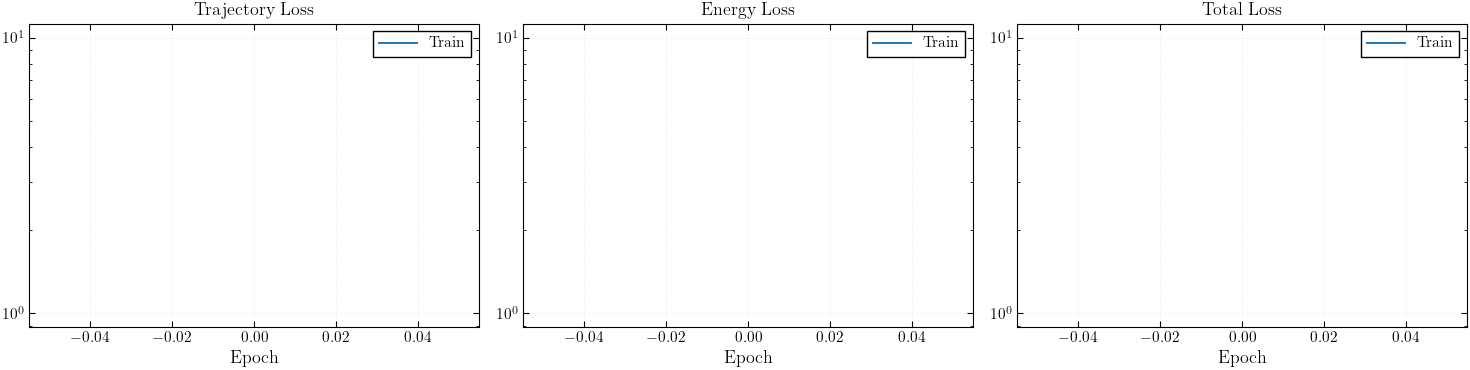

In [50]:
plt.figure(figsize=(15,4))

epochs_axis = range(len(train_q_loss))

plt.subplot(1,3,1)
plt.plot(epochs_axis, train_q_loss, label="Train")
# plt.plot(epochs_axis, val_q_loss, '--', label="Val")
plt.yscale("log")
plt.title("Trajectory Loss")
plt.xlabel("Epoch")
plt.grid(True)
plt.legend()

plt.subplot(1,3,2)
plt.plot(epochs_axis, train_qdot_loss, label="Train")
# plt.plot(epochs_axis, val_loss_energy, '--', label="Val")
plt.yscale("log")
plt.title("Energy Loss")
plt.xlabel("Epoch")
plt.grid(True)
plt.legend()

plt.subplot(1,3,3)
plt.plot(epochs_axis, train_total_loss, label="Train")
# plt.plot(epochs_axis, val_total_loss, '--', label="Val")
plt.yscale("log")
plt.title("Total Loss")
plt.xlabel("Epoch")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()



In [54]:
traj_n = 1 #should be in validatioon set
seq_len_val = 5000 / downsample_factor

val_dataset = SequenceDataset([val_runs[traj_n]], seq_len_val)  # Fixed to max for full evaluation
val_dataloader = DataLoader(val_dataset, batch_size=1, shuffle=False, drop_last=False)


dynamics.eval()
for x_seq_batch, u_seq_batch, dq_seq_batch in val_dataloader:
    x_seq_batch = x_seq_batch.to(device)
    u_seq_batch = u_seq_batch.to(device)
    dq_seq_batch = dq_seq_batch.to(device)

    # initialize with q0, p0
    q0 = x_seq_batch[:, 0, :q_dim]
    dq0 = dq_seq_batch[:, 0, :]
    # q2 = q0[:, 1:2]
    # M0 = mass_nn(q2)
    # p0 = torch.bmm(M0, dq0.unsqueeze(-1)).squeeze(-1)
    x_pred = torch.cat([q0, dq0], dim=-1).clone().detach().requires_grad_(True)

    preds = []
    for k in range(0,int(seq_len_val)):
        if k < u_seq_batch.size(1):
            u_step = u_seq_batch[:, k, :]
        else:
            u_step = torch.zeros_like(u_seq_batch[:, 0, :])

        f = lambda tt, xx, u=u_step: dynamics(tt, xx, u)
        x_pred = rk4_step(f, x_pred, k*dt, dt)
        preds.append(x_pred.detach())  # detach from graph to avoid memory buildup


# Stack predictions
preds = torch.stack(preds, dim=0)        # (T, 1, 4)
preds = preds.squeeze(1).cpu().numpy()   # (T, 4)

# Predicted trajectories
pred_traj = {
    "theta1": preds[:, 0],
    "theta2": preds[:, 1],
    "state3": preds[:, 2],   # dq1
    "state4": preds[:, 3],   # dq2
}

# Ground truth trajectories
true_traj = {
    "theta1": x_seq_batch[0, :, 0].cpu().numpy(),
    "theta2": x_seq_batch[0, :, 1].cpu().numpy(),
    "state3": dq_seq_batch[0, :, 0].cpu().numpy(),  # dq1
    "state4": dq_seq_batch[0, :, 1].cpu().numpy(),  # dq2
}

In [56]:
import matplotlib.pyplot as plt

# Labels (velocity case)
state3_title = "Joint 1 Velocity"
state3_label = "dθ₁ / dt [rad/s]"
state4_title = "Joint 2 Velocity"
state4_label = "dθ₂ / dt [rad/s]"
# Ensure same horizon
T = min(
    len(pred_traj["theta1"]),
    len(true_traj["theta1"])
)

time = np.arange(T) * dt

fig, axs = plt.subplots(2, 2, figsize=(14, 9))

# -------------------------
# Joint 1 Angle
# -------------------------
axs[0, 0].plot(time, true_traj["theta1"][:T],
               label="Ground Truth", linewidth=2.5)
axs[0, 0].plot(time, pred_traj["theta1"][:T],
               '--', label="Predicted", linewidth=2)
axs[0, 0].set_title("Joint 1 Angle", fontweight='bold')
axs[0, 0].set_ylabel("θ₁ [rad]")
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# -------------------------
# Joint 1 Velocity
# -------------------------
axs[0, 1].plot(time, true_traj["state3"][:T],
               label="Ground Truth", linewidth=2.5)
axs[0, 1].plot(time, pred_traj["state3"][:T],
               '--', label="Predicted", linewidth=2)
axs[0, 1].set_title("Joint 1 Velocity", fontweight='bold')
axs[0, 1].set_ylabel("dθ₁ / dt [rad/s]")
axs[0, 1].legend()
axs[0, 1].grid(True, alpha=0.3)

# -------------------------
# Joint 2 Angle
# -------------------------
axs[1, 0].plot(time, true_traj["theta2"][:T],
               label="Ground Truth", linewidth=2.5)
axs[1, 0].plot(time, pred_traj["theta2"][:T],
               '--', label="Predicted", linewidth=2)
axs[1, 0].set_title("Joint 2 Angle", fontweight='bold')
axs[1, 0].set_ylabel("θ₂ [rad]")
axs[1, 0].set_xlabel("Time [s]")
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

# -------------------------
# Joint 2 Velocity
# -------------------------
axs[1, 1].plot(time, true_traj["state4"][:T],
               label="Ground Truth", linewidth=2.5)
axs[1, 1].plot(time, pred_traj["state4"][:T],
               '--', label="Predicted", linewidth=2)
axs[1, 1].set_title("Joint 2 Velocity", fontweight='bold')
axs[1, 1].set_ylabel("dθ₂ / dt [rad/s]")
axs[1, 1].set_xlabel("Time [s]")
axs[1, 1].legend()
axs[1, 1].grid(True, alpha=0.3)

plt.suptitle(f"Model Validation – Trajectory {traj_n}",
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ============================================================
# ERROR METRICS
# ============================================================

theta1_rmse = np.sqrt(np.mean(
    (true_traj["theta1"][:T] - pred_traj["theta1"][:T])**2
))
theta2_rmse = np.sqrt(np.mean(
    (true_traj["theta2"][:T] - pred_traj["theta2"][:T])**2
))
state3_rmse = np.sqrt(np.mean(
    (true_traj["state3"][:T] - pred_traj["state3"][:T])**2
))
state4_rmse = np.sqrt(np.mean(
    (true_traj["state4"][:T] - pred_traj["state4"][:T])**2
))

print("\n" + "=" * 60)
print("PREDICTION ERROR METRICS")
print("=" * 60)
print(f"θ₁ RMSE: {theta1_rmse:.6f} rad")
print(f"θ₂ RMSE: {theta2_rmse:.6f} rad")
print(f"dθ₁/dt RMSE: {state3_rmse:.6f} rad/s")
print(f"dθ₂/dt RMSE: {state4_rmse:.6f} rad/s")
print("=" * 60)

# Relative errors
theta1_mean = np.mean(np.abs(true_traj["theta1"][:T]))
theta2_mean = np.mean(np.abs(true_traj["theta2"][:T]))

if theta1_mean > 0:
    print(f"θ₁ relative error: {100 * theta1_rmse / theta1_mean:.2f}%")
if theta2_mean > 0:
    print(f"θ₂ relative error: {100 * theta2_rmse / theta2_mean:.2f}%")
print("=" * 60)

RuntimeError: latex was not able to process the following string:
b'\\u03b8\\u2081 [rad]'

Here is the full command invocation and its output:

latex -interaction=nonstopmode --halt-on-error file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.26 (TeX Live 2024/Homebrew) (preloaded format=latex)
 restricted \write18 enabled.
entering extended mode
(./file.tex
LaTeX2e <2023-11-01> patch level 1
L3 programming layer <2024-02-20>

(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/article.
cls
Document Class: article 2023/05/17 v1.4n Standard LaTeX document class

(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/size10.c
lo))
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/type1cm/type1
cm.sty)
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/cm-super/type
1ec.sty
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/t1cmr.fd
))
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/

Error in callback <function _draw_all_if_interactive at 0x11b3af1c0> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: latex was not able to process the following string:
b'\\u03b8\\u2081 [rad]'

Here is the full command invocation and its output:

latex -interaction=nonstopmode --halt-on-error file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.26 (TeX Live 2024/Homebrew) (preloaded format=latex)
 restricted \write18 enabled.
entering extended mode
(./file.tex
LaTeX2e <2023-11-01> patch level 1
L3 programming layer <2024-02-20>

(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/article.
cls
Document Class: article 2023/05/17 v1.4n Standard LaTeX document class

(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/size10.c
lo))
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/type1cm/type1
cm.sty)
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/cm-super/type
1ec.sty
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/t1cmr.fd
))
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/

RuntimeError: latex was not able to process the following string:
b'\\u03b8\\u2081 [rad]'

Here is the full command invocation and its output:

latex -interaction=nonstopmode --halt-on-error file.tex

This is pdfTeX, Version 3.141592653-2.6-1.40.26 (TeX Live 2024/Homebrew) (preloaded format=latex)
 restricted \write18 enabled.
entering extended mode
(./file.tex
LaTeX2e <2023-11-01> patch level 1
L3 programming layer <2024-02-20>

(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/article.
cls
Document Class: article 2023/05/17 v1.4n Standard LaTeX document class

(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/size10.c
lo))
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/type1cm/type1
cm.sty)
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/cm-super/type
1ec.sty
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/base/t1cmr.fd
))
(/opt/homebrew/Cellar/texlive/20240312/share/texmf-dist/tex/latex/

<Figure size 1400x900 with 4 Axes>

In [57]:
import numpy as np

T = min(len(pred_traj["theta1"]), len(true_traj["theta1"]))

model_name = "HNN_sim_no_noise_linear_friction"  # change per model: "LS", "HNN", "baseline", etc.

np.savez(
    f"results_{model_name}.npz",
    model_name=model_name,
    dt=dt,
    traj_n=traj_n,
    # ground truth
    true_theta1=true_traj["theta1"][:T],
    true_theta2=true_traj["theta2"][:T],
    true_dtheta1=true_traj["state3"][:T],
    true_dtheta2=true_traj["state4"][:T],
    # predicted
    pred_theta1=pred_traj["theta1"][:T],
    pred_theta2=pred_traj["theta2"][:T],
    pred_dtheta1=pred_traj["state3"][:T],
    pred_dtheta2=pred_traj["state4"][:T],
)

print(f"Saved results_{model_name}.npz  ({T} steps)")

Saved results_HNN_sim_no_noise_linear_friction.npz  (500 steps)


In [ ]:
# Save subnetwork/state (no duplicate keys)
# torch.save({
#     'mass_nn': mass_nn.state_dict(),
#     'diss_nn': diss_nn.state_dict(),
#     'actuator_nn': actuator_nn.state_dict(),
# }, "LS_state_no_noise.pth")
# print("Saved modular model state to modular_hnn_state.pth")

# # Plot training loss (use accumulated history)
# plt.figure(figsize=(8,5))
# plt.plot(range(1, len(loss_history)+1), loss_history, label="Training Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.yscale("log")
# plt.title("Training Loss Over Epochs")
# plt.legend()
# plt.grid(True)
# plt.show()

Saved modular model state to modular_hnn_state.pth
